In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import linear_model

In [2]:
eth = pd.read_csv('data/coin_Ethereum.csv')
btc = pd.read_csv('data/coin_Bitcoin.csv')

eth['Date'] = pd.to_datetime(eth['Date'])
btc['Date'] = pd.to_datetime(btc['Date'])

eth = eth.sort_values(by='Date', ascending=True)

In [3]:
d_min, d_max = eth['Date'].min(), eth['Date'].max()

print(f'ETH - data inicial: {d_min}, data final: {d_max}')

ETH - data inicial: 2015-08-08 23:59:59, data final: 2021-07-06 23:59:59


In [4]:
d_min, d_max = eth['Date'].min(), eth['Date'].max()

print(f'data inicial: {d_min}, data final: {d_max}')

data inicial: 2015-08-08 23:59:59, data final: 2021-07-06 23:59:59


In [5]:
b_min, b_max = btc['Date'].min(), btc['Date'].max()

print(f'BTC - data inicial: {b_min}, data final: {b_max}')

BTC - data inicial: 2013-04-29 23:59:59, data final: 2021-07-06 23:59:59


In [6]:
filtro = btc['Date'] >= d_min

btc = btc[filtro].copy()
btc = btc.sort_values(by='Date', ascending=True).reset_index(drop=True)

In [7]:
features = ['High','Low','Open','Close']

for i in features:
    corr = np.corrcoef(btc[i], eth[i])

    print(f'Correlação {i}: {corr[0,1]}')


Correlação High: 0.9029174879246604
Correlação Low: 0.9056573401218898
Correlação Open: 0.904183238234174
Correlação Close: 0.9041473285726195


In [8]:
df = btc[['Close']].copy()
df['ETH_close'] = eth['Close'].copy()
df = df.round(5)
df = df.rename(columns={'Close' : 'BTC_close'})
df

,BTC_close,ETH_close
0,260.99701,0.75332
1,265.08301,0.70190
2,264.47000,0.70845
3,270.38599,1.06786
4,266.37601,1.21744
...,...,...
2155,33897.04859,2150.04036
2156,34668.54840,2226.11428
2157,35287.77977,2321.72411
2158,33746.00246,2198.58246


In [9]:
model = linear_model.LinearRegression()
model.fit(df[['BTC_close']], df['ETH_close'])

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.04]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['BTC_close']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-15.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [10]:
a, b = model.coef_[0], model.intercept_
print(f'y = {a:.3f}x + {b:.3f}')

y = 0.044x + -15.017


In [11]:
predict = model.predict(df[['BTC_close']])
predict

array([  -3.63698659,   -3.45882906,   -3.48555749, ..., 1523.59871134,
       1456.3742288 , 1477.70390524], shape=(2160,))

In [12]:
model.score(df[['BTC_close']], df['ETH_close'])

0.8174823918415715

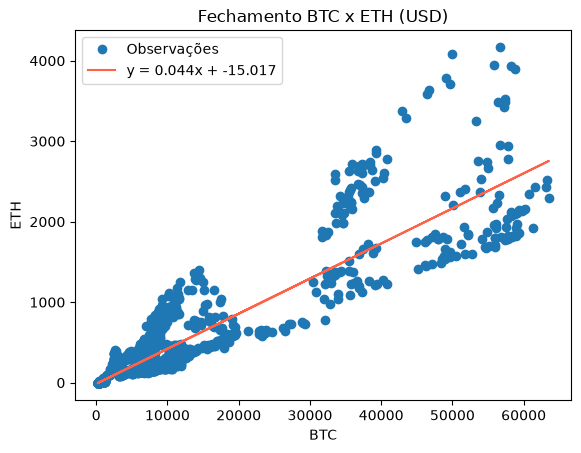

In [13]:
plt.Figure(figsize=(20,10))
plt.Figure(dpi=400)

plt.plot(df['BTC_close'], df['ETH_close'], 'o')
plt.plot(df['BTC_close'], predict, color='tomato')

plt.title('Fechamento BTC x ETH (USD)')
plt.xlabel('BTC')
plt.ylabel('ETH')
plt.legend(['Observações', f'y = {a:.3f}x + {b:.3f}'])